## Step 1 — Load and inspect the reduced dataset

In [1]:

import pandas as pd
import numpy as np
from google.colab import files
from IPython.display import display

# Upload the reduced 111-feature dataset
uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nTarget distribution:")
if "phishing" in df.columns:
    display(df["phishing"].value_counts().sort_index())
    print("\nTarget proportions:")
    display(df["phishing"].value_counts(normalize=True).sort_index())
else:
    print("Target column 'phishing' not found. Check the column names.")

if "_split" in df.columns:
    print("\nExisting train/test split:")
    display(df["_split"].value_counts())


Saving phishguard_111_reduced_50_features.csv to phishguard_111_reduced_50_features.csv
Dataset loaded successfully!
Dataset shape: (87197, 52)

First 5 rows:


,qty_slash_url,time_domain_activation,directory_length,length_url,qty_dot_domain,ttl_hostname,asn_ip,qty_slash_directory,time_response,time_domain_expiration,...,qty_plus_url,qty_exclamation_directory,qty_slash_params,qty_percent_params,qty_underline_params,qty_comma_file,tld_present_params,qty_tilde_directory,phishing,_split
0,1,-1,9,96,2,266,47814,1,0.853279,-1,...,0,0,0,0,0,0,0,0,1,train
1,0,265,-1,17,2,599,40676,-1,0.677885,99,...,0,-1,-1,-1,-1,-1,-1,-1,0,train
2,0,7049,-1,25,2,3592,26496,-1,0.416377,986,...,0,-1,-1,-1,-1,-1,-1,-1,0,train
3,3,232,17,29,1,14378,55470,3,0.585415,132,...,0,0,-1,-1,-1,0,-1,0,1,train
4,0,5833,-1,17,2,7199,27357,-1,0.614896,375,...,0,-1,-1,-1,-1,-1,-1,-1,0,train



Column names:
['qty_slash_url', 'time_domain_activation', 'directory_length', 'length_url', 'qty_dot_domain', 'ttl_hostname', 'asn_ip', 'qty_slash_directory', 'time_response', 'time_domain_expiration', 'qty_redirects', 'qty_mx_servers', 'domain_length', 'file_length', 'domain_spf', 'qty_hyphen_directory', 'qty_nameservers', 'qty_vowels_domain', 'tls_ssl_certificate', 'qty_dot_url', 'qty_ip_resolved', 'qty_dot_params', 'qty_tld_url', 'qty_at_url', 'qty_hyphen_domain', 'qty_hyphen_url', 'params_length', 'qty_params', 'url_shortened', 'qty_dot_directory', 'qty_hyphen_file', 'qty_dot_file', 'qty_equal_directory', 'qty_underline_directory', 'qty_underline_url', 'qty_percent_url', 'qty_underline_file', 'qty_percent_file', 'qty_equal_url', 'domain_in_ip', 'qty_percent_directory', 'qty_equal_params', 'qty_plus_url', 'qty_exclamation_directory', 'qty_slash_params', 'qty_percent_params', 'qty_underline_params', 'qty_comma_file', 'tld_present_params', 'qty_tilde_directory', 'phishing', '_split']

,count
phishing,
0,56706
1,30491



Target proportions:


,proportion
phishing,
0,0.650321
1,0.349679



Existing train/test split:


,count
_split,
train,61037
test,26160


###Step 1 — Dataset inspection: conclusion

* The dataset is imbalanced, with substantially more legitimate samples than phishing samples.
* The existing split contains 61,037 training rows and 26,160 test rows, which is approximately 70:30.
* We'll recreate a stratified 70:30 split from the full dataset to ensure that the experiment follows the required procedure, then balance only the training data.

##Step 2 — Stratified 70:30 split and 50:50 training balance

In [2]:

from sklearn.model_selection import train_test_split
from sklearn.utils import resample
from IPython.display import display

# Separate features and target
feature_columns = [col for col in df.columns
                   if col not in ["phishing", "_split"]]

X = df[feature_columns].copy()
y = df["phishing"].copy()

# Step 1: Stratified 70:30 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Original split:")
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining class counts before balancing:")
display(y_train.value_counts().sort_index())

print("\nTesting class counts (untouched):")
display(y_test.value_counts().sort_index())

# Step 2: Combine training features and labels
train_data = X_train.copy()
train_data["phishing"] = y_train.to_numpy()

# Separate the training classes
class_0 = train_data[train_data["phishing"] == 0]
class_1 = train_data[train_data["phishing"] == 1]

# Undersample majority class to match minority class
n_samples = min(len(class_0), len(class_1))

class_0_balanced = resample(
    class_0,
    replace=False,
    n_samples=n_samples,
    random_state=42
)

class_1_balanced = resample(
    class_1,
    replace=False,
    n_samples=n_samples,
    random_state=42
)

# Combine and shuffle the balanced training data
train_balanced = pd.concat(
    [class_0_balanced, class_1_balanced],
    ignore_index=True
).sample(frac=1, random_state=42).reset_index(drop=True)

# Final training features and target
X_train_balanced = train_balanced[feature_columns]
y_train_balanced = train_balanced["phishing"]

print("\nBalanced training shape:", X_train_balanced.shape)
print("Balanced test shape:", X_test.shape)

print("\nBalanced training class counts:")
display(y_train_balanced.value_counts().sort_index())

print("\nBalanced training proportions:")
display(y_train_balanced.value_counts(normalize=True).sort_index())

print("\nTest class counts (unchanged):")
display(y_test.value_counts().sort_index())

print("\nTest proportions (unchanged):")
display(y_test.value_counts(normalize=True).sort_index())


Original split:
Training shape: (61037, 50)
Testing shape: (26160, 50)

Training class counts before balancing:


,count
phishing,
0,39694
1,21343



Testing class counts (untouched):


,count
phishing,
0,17012
1,9148



Balanced training shape: (42686, 50)
Balanced test shape: (26160, 50)

Balanced training class counts:


...

,proportion
phishing,
0,0.5
1,0.5



Test class counts (unchanged):


,count
phishing,
0,17012
1,9148



Test proportions (unchanged):


,proportion
phishing,
0,0.650306
1,0.349694


###Step 2 — Conclusion
- The stratified split is approximately 70:30: 61,037 training rows and 26,160 test rows.
- Training data is balanced to 21,343 legitimate + 21,343 phishing = 42,686 rows.
- The test set remains untouched at 26,160 rows, with its original 65:35 class distribution.

##Step 3 — Check train–test data leakage

In [3]:

# Check exact overlap of feature rows between training and test sets

train_rows = set(
    map(tuple, X_train_balanced.to_numpy())
)

test_rows = set(
    map(tuple, X_test.to_numpy())
)

overlapping_rows = train_rows.intersection(test_rows)

print("Unique training feature rows:", len(train_rows))
print("Unique test feature rows:", len(test_rows))
print("Overlapping unique feature rows:", len(overlapping_rows))

if len(overlapping_rows) == 0:
    print("\nConclusion: No exact feature-row overlap detected.")
else:
    print("\nWARNING: Exact feature rows occur in both training and test sets.")

# Also check duplicates within each split
print("\nDuplicate rows within balanced training set:",
      X_train_balanced.duplicated().sum())

print("Duplicate rows within test set:",
      X_test.duplicated().sum())


Unique training feature rows: 42681
Unique test feature rows: 26160
Overlapping unique feature rows: 4


Duplicate rows within balanced training set: 5
Duplicate rows within test set: 0


###Conclusion
- 4 overlapping feature rows between training and test sets.
- 5 duplicate feature rows within the balanced training set.
- 0 duplicate feature rows within the test set.

###Investigate overlapping rows

In [5]:

import numpy as np
import pandas as pd

# Preserve labels alongside the original, unbalanced training data
original_train = X_train.copy()
original_train["phishing"] = y_train.to_numpy()

test_data = X_test.copy()
test_data["phishing"] = y_test.to_numpy()

# Identify exact feature vectors present in both sets
train_features = set(map(tuple, X_train.to_numpy()))
test_features = set(map(tuple, X_test.to_numpy()))
overlap_features = train_features.intersection(test_features)

print("Number of overlapping feature vectors:", len(overlap_features))

# Investigate each overlapping vector and compare its labels
for i, features in enumerate(sorted(overlap_features), start=1):
    train_mask = np.all(
        X_train.to_numpy() == np.array(features),
        axis=1
    )
    test_mask = np.all(
        X_test.to_numpy() == np.array(features),
        axis=1
    )

    train_labels = y_train.iloc[np.where(train_mask)[0]].tolist()
    test_labels = y_test.iloc[np.where(test_mask)[0]].tolist()

    print(f"\nOverlap {i}")
    print("Training labels:", train_labels)
    print("Test labels:", test_labels)
    print("Labels agree:", all(
        train_label == test_label
        for train_label in train_labels
        for test_label in test_labels
    ))


Number of overlapping feature vectors: 5

Overlap 1
Training labels: [0]
Test labels: [0]
Labels agree: True

Overlap 2
Training labels: [0]
Test labels: [0]
Labels agree: True

Overlap 3
Training labels: [0]
Test labels: [0]
Labels agree: True

Overlap 4
Training labels: [0]
Test labels: [0]
Labels agree: True

Overlap 5
Training labels: [1]
Test labels: [1]
Labels agree: True


###Conclusion
- 5 overlapping feature vectors found.
- 5/5 have matching labels — no conflicting labels among the overlaps.
- The overlap is still a potential evaluation concern because identical feature vectors appear in both sets, even though their labels agree.
- The balanced training set also has 5 duplicate feature rows internally; the test set has none.

##Step 4 — Train the four machine learning models

In [6]:

import time
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=100,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    )
}

trained_models = {}
training_times = {}

for name, model in models.items():
    start_time = time.perf_counter()
    model.fit(X_train_balanced, y_train_balanced)
    elapsed = time.perf_counter() - start_time

    trained_models[name] = model
    training_times[name] = elapsed

    print(f"{name}: training completed in {elapsed:.2f} seconds")

print("\nAll four models trained successfully.")

training_time_df = pd.DataFrame({
    "Model": list(training_times.keys()),
    "Training Time (seconds)": list(training_times.values())
})

display(training_time_df)


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression: training completed in 25.67 seconds
Decision Tree: training completed in 0.85 seconds
Random Forest: training completed in 7.51 seconds
XGBoost: training completed in 2.07 seconds

All four models trained successfully.


,Model,Training Time (seconds)
0,Logistic Regression,25.670549
1,Decision Tree,0.848692
2,Random Forest,7.510067
3,XGBoost,2.073140


###Conclusion
Logistic Regression took the longest and reached its iteration limit before converging. This doesn't automatically mean the model is unusable, but we should address it before relying on its results. Since the feature values may have different scales, feature standardization is the appropriate next fix for Logistic Regression.

We can keep the three tree-based models as trained and retrain Logistic Regression with a StandardScaler inside a pipeline. This avoids data leakage because the scaler learns its parameters from training data only.

###Step 4A — Fix Logistic Regression convergence

In [7]:

import time
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=5000, random_state=42)
)

start_time = time.perf_counter()
lr_model.fit(X_train_balanced, y_train_balanced)
lr_training_time = time.perf_counter() - start_time

trained_models["Logistic Regression"] = lr_model
training_times["Logistic Regression"] = lr_training_time

print(f"Logistic Regression retraining time: {lr_training_time:.2f} seconds")
print("Iterations used:", lr_model.named_steps["logisticregression"].n_iter_)
print("Convergence limit:", lr_model.named_steps["logisticregression"].max_iter)


Logistic Regression retraining time: 3.94 seconds
Iterations used: [55]
Convergence limit: 5000


###Step 4 conclusion — Model training completed
Standardization reduced Logistic Regression's training time from 25.67 seconds to 3.94 seconds, and it converged well before the 5,000-iteration limit.

Your trained_models dictionary now contains all four models, with the updated, scaled Logistic Regression pipeline.

##Step 5 — Evaluate all four models

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Prediction Time (seconds)
0,XGBoost,0.9662,0.9366,0.9691,0.9526,0.9947,0.3034
1,Random Forest,0.9650,0.9329,0.9697,0.9510,0.9947,1.3190
2,Decision Tree,0.9482,0.9102,0.9450,0.9273,0.9474,0.0174
3,Logistic Regression,0.9242,0.8541,0.9446,0.8971,0.9791,0.0537


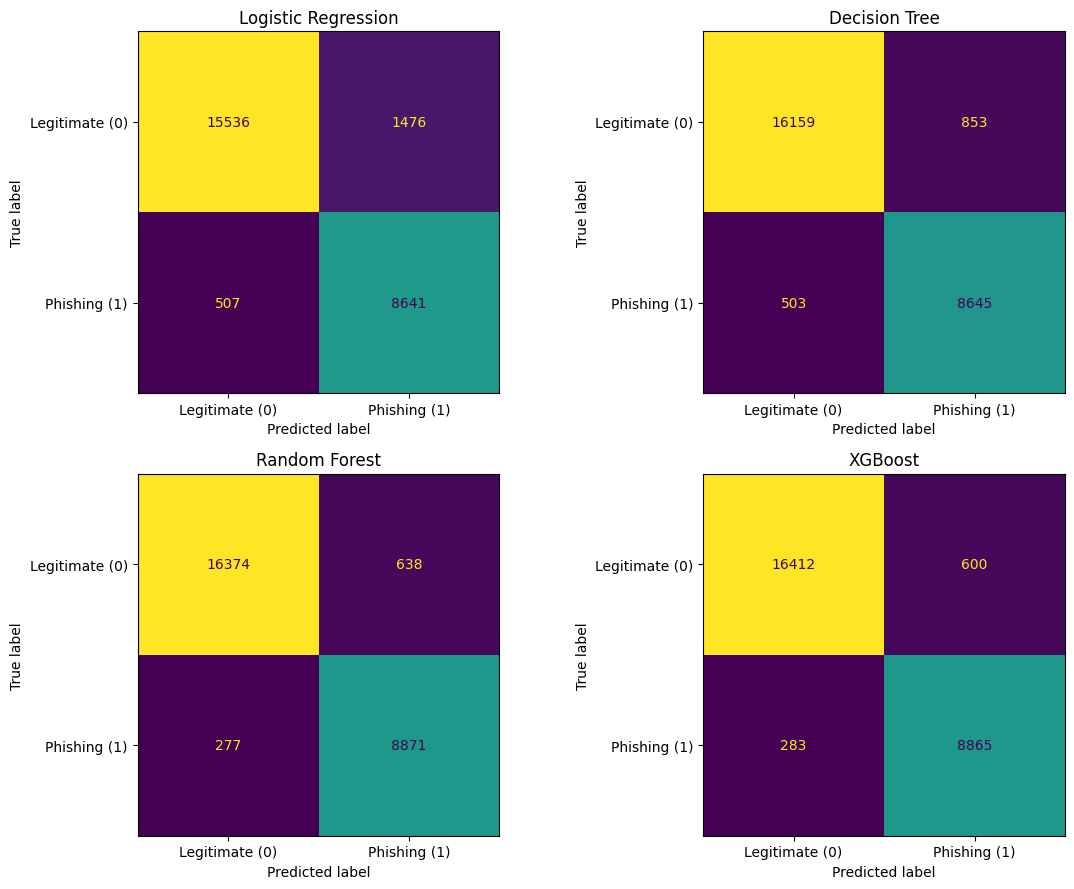

In [8]:

import time
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

results = []
test_predictions = {}
test_probabilities = {}

for name, model in trained_models.items():
    # Measure prediction time
    start_time = time.perf_counter()
    y_pred = model.predict(X_test)
    prediction_time = time.perf_counter() - start_time

    # Get scores for the positive class (phishing = 1)
    y_prob = model.predict_proba(X_test)[:, 1]

    test_predictions[name] = y_pred
    test_probabilities[name] = y_prob

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Prediction Time (seconds)": prediction_time
    })

results_df = pd.DataFrame(results).sort_values(
    by="F1 Score", ascending=False
).reset_index(drop=True)

display(results_df.round(4))

# Plot confusion matrices
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()

for ax, (name, y_pred) in zip(axes, test_predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    display_obj = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Legitimate (0)", "Phishing (1)"]
    )
    display_obj.plot(ax=ax, values_format="d", colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()


###Step 5 conclusion — Model evaluation
- XGBoost performed best overall, achieving 96.62% accuracy, 95.26% F1-score, and 99.47% ROC-AUC.
- Random Forest was a close second, with 96.50% accuracy and the highest phishing recall at 96.97%.
- Decision Tree had the fastest prediction time at 0.0174 seconds, but its predictive performance was lower than XGBoost and Random Forest.
- Logistic Regression performed the weakest overall, with 92.42% accuracy and an 89.71% F1-score.
- XGBoost and Random Forest both achieved excellent ROC-AUC scores of 0.9947, indicating strong ability to distinguish between phishing and legitimate samples.

Preliminary recommendation: XGBoost is the leading candidate for PhishGuard because it offers the best overall balance of accuracy, precision, recall, and F1-score. Random Forest is also worth considering because its phishing recall is slightly higher.

##Step 6 — Model comparison graphs

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (seconds),Prediction Time (seconds),Model Size (MB)
0,XGBoost,0.9662,0.9366,0.9691,0.9526,0.9947,2.0731,0.3034,0.2894
1,Random Forest,0.9650,0.9329,0.9697,0.9510,0.9947,7.5101,1.3190,32.0670
2,Decision Tree,0.9482,0.9102,0.9450,0.9273,0.9474,0.8487,0.0174,0.2669
3,Logistic Regression,0.9242,0.8541,0.9446,0.8971,0.9791,3.9398,0.0537,0.0039


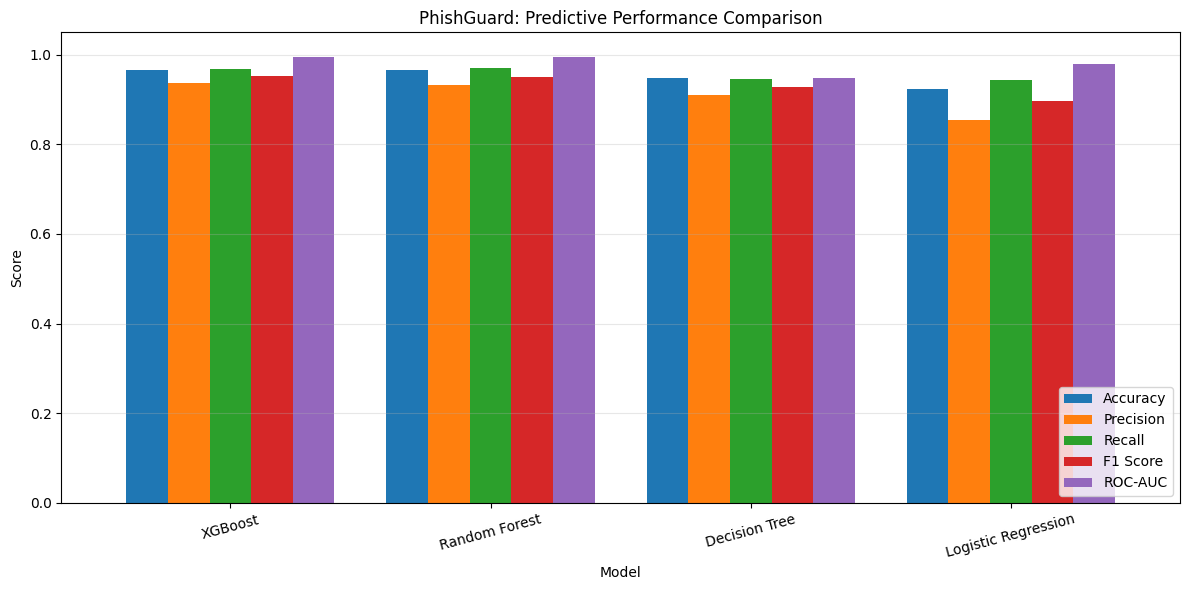

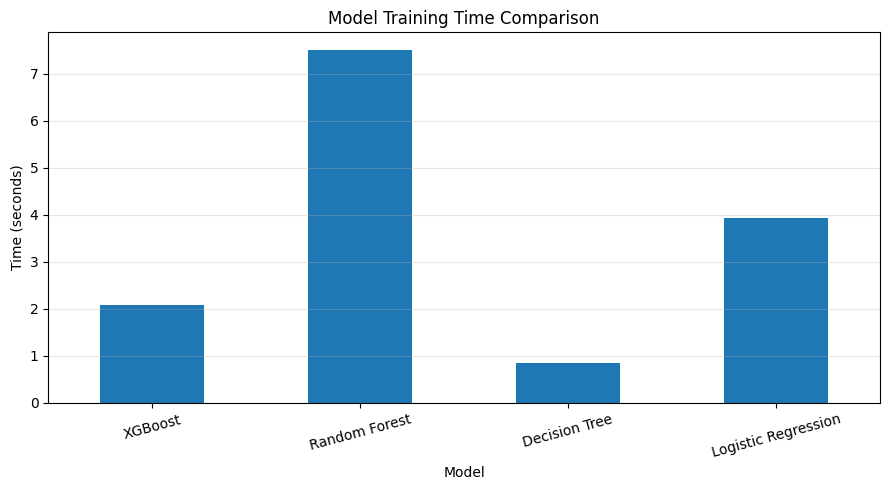

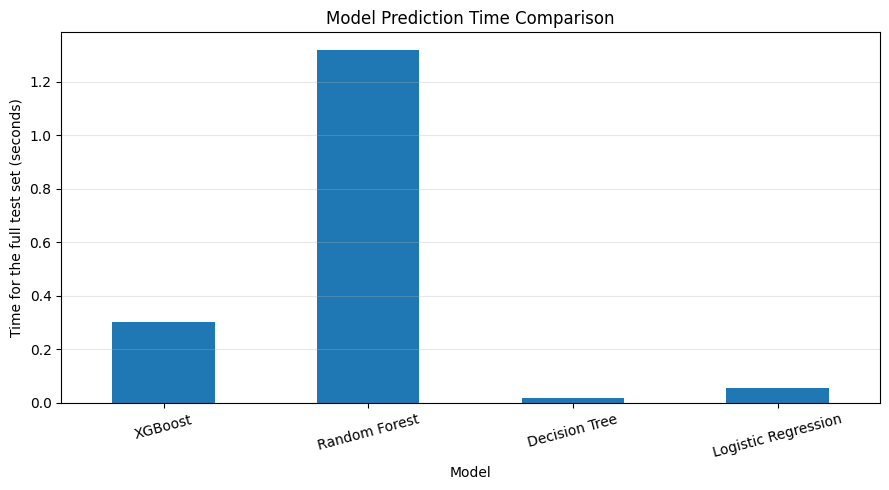

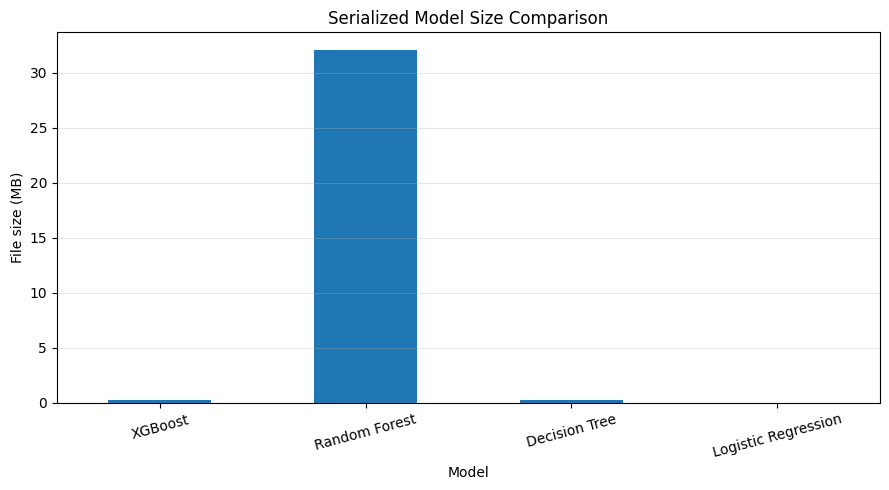

In [9]:

import os
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Prepare comparison data
comparison_df = results_df.copy()

comparison_df["Training Time (seconds)"] = comparison_df["Model"].map(
    training_times
)

# 2. Estimate serialized model size
model_sizes = {}

for name, model in trained_models.items():
    temp_path = f"/tmp/phishguard_{name.replace(' ', '_')}.joblib"
    joblib.dump(model, temp_path)
    model_sizes[name] = os.path.getsize(temp_path) / (1024 ** 2)  # MB
    os.remove(temp_path)

comparison_df["Model Size (MB)"] = comparison_df["Model"].map(model_sizes)

# Display the complete comparison table
display(
    comparison_df[
        [
            "Model",
            "Accuracy",
            "Precision",
            "Recall",
            "F1 Score",
            "ROC-AUC",
            "Training Time (seconds)",
            "Prediction Time (seconds)",
            "Model Size (MB)"
        ]
    ].round(4)
)

# 3. Plot predictive performance metrics
performance_metrics = [
    "Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"
]

ax = comparison_df.set_index("Model")[performance_metrics].plot(
    kind="bar", figsize=(12, 6), ylim=(0, 1.05), width=0.8
)
ax.set_title("PhishGuard: Predictive Performance Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# 4. Plot training time
ax = comparison_df.set_index("Model")[
    "Training Time (seconds)"
].plot(kind="bar", figsize=(9, 5))
ax.set_title("Model Training Time Comparison")
ax.set_ylabel("Time (seconds)")
ax.set_xlabel("Model")
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# 5. Plot prediction time
ax = comparison_df.set_index("Model")[
    "Prediction Time (seconds)"
].plot(kind="bar", figsize=(9, 5))
ax.set_title("Model Prediction Time Comparison")
ax.set_ylabel("Time for the full test set (seconds)")
ax.set_xlabel("Model")
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# 6. Plot serialized model size
ax = comparison_df.set_index("Model")[
    "Model Size (MB)"
].plot(kind="bar", figsize=(9, 5))
ax.set_title("Serialized Model Size Comparison")
ax.set_ylabel("File size (MB)")
ax.set_xlabel("Model")
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


###Step 6 conclusion — Model comparison
- Predictive performance: XGBoost achieved the highest accuracy (96.62%) and F1-score (95.26%), with a ROC-AUC of 99.47%.
- Training time: XGBoost trained in approximately 2.07 seconds, faster than Random Forest (7.51 seconds).
- Prediction time: XGBoost predicted the entire test set in approximately 0.30 seconds. Random Forest took 1.32 seconds.
- Model size: Random Forest had the largest serialized model size, approximately 32 MB. XGBoost's model was much smaller, making it a more practical deployment candidate than Random Forest.

###Final model selection: XGBoost
XGBoost is selected because it provides the best overall balance of predictive performance, training efficiency, prediction speed, and model size among the four evaluated models.

Random Forest has a marginally higher phishing recall (96.97% versus 96.91%), but XGBoost achieves better accuracy, precision, and F1-score while being faster in both training and prediction.


Decision: Use XGBoost as the final candidate for PhishGuard's website integration, subject to the remaining explainability checks and final validation. The current evaluation also found five identical feature vectors across the training and test sets, so a duplicate-controlled evaluation would strengthen confidence in the reported performance.

##Step 7 — Generate SHAP explanations

###7.1 Install and import SHAP

In [10]:

%pip install -q shap


In [11]:

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Selected final model
final_model = trained_models["XGBoost"]

print("Model selected:", type(final_model).__name__)
print("Test dataset shape:", X_test.shape)


Model selected: XGBClassifier
Test dataset shape: (26160, 50)


###7.2 Global feature importance — SHAP summary plot

Top 20 globally important features:


,Feature,Mean Absolute SHAP
0,qty_slash_url,2.819586
1,time_domain_activation,1.461031
2,length_url,0.702935
3,directory_length,0.486578
4,qty_dot_domain,0.471975
5,ttl_hostname,0.361410
6,asn_ip,0.326894
7,time_response,0.250332
8,time_domain_expiration,0.222666
9,domain_length,0.184762


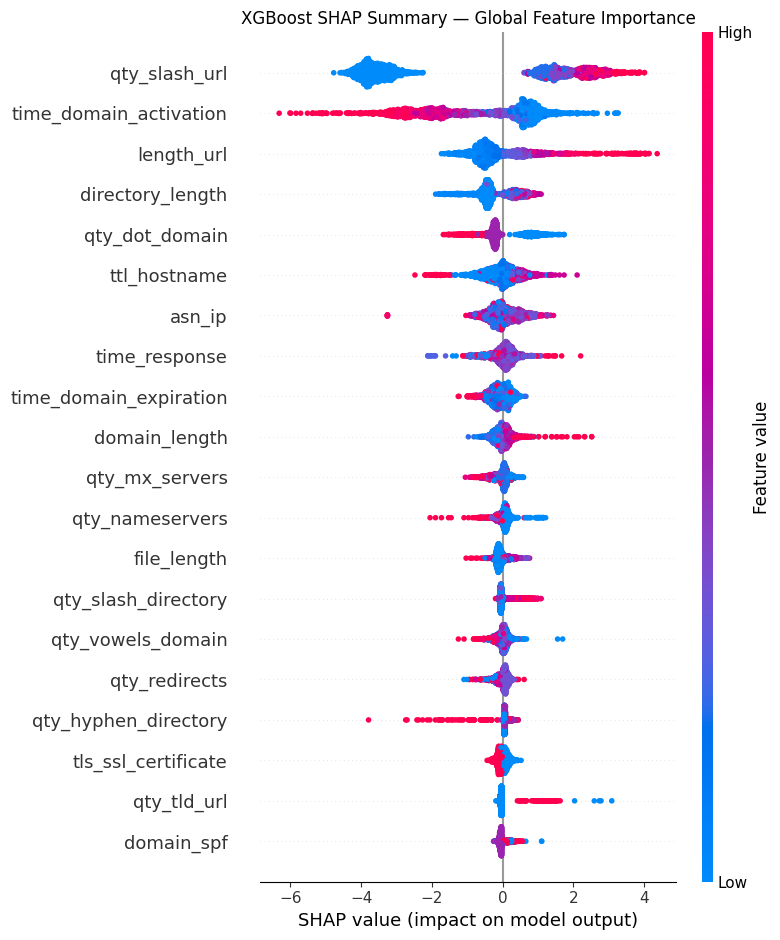

In [12]:

# Use a reproducible sample of the test data
X_shap = X_test.sample(
    n=min(2000, len(X_test)),
    random_state=42
)

# Explain XGBoost predictions
explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_shap)

# Global feature importance: mean absolute SHAP value
mean_abs_shap = np.abs(shap_values).mean(axis=0)

global_importance = pd.DataFrame({
    "Feature": X_shap.columns,
    "Mean Absolute SHAP": mean_abs_shap
}).sort_values(
    "Mean Absolute SHAP", ascending=False
).reset_index(drop=True)

print("Top 20 globally important features:")
display(global_importance.head(20).round(6))

# SHAP summary plot
shap.summary_plot(
    shap_values,
    X_shap,
    max_display=20,
    show=False
)
plt.title("XGBoost SHAP Summary — Global Feature Importance")
plt.tight_layout()
plt.show()


###How to interpret it:
- Features near the top have greater average influence on predictions.
- Each dot represents a sample.
- Dot colour indicates the feature value: typically red for high and blue for low.
- SHAP values to the right push the prediction toward phishing; values to the left push it toward legitimate, for the standard binary XGBoost output explained here.

###7.3 Local explanation — one test sample

Test sample index: 57778
Actual label: 0 (Legitimate)
Predicted label: 0 (Legitimate)
Predicted phishing probability: 0.0008


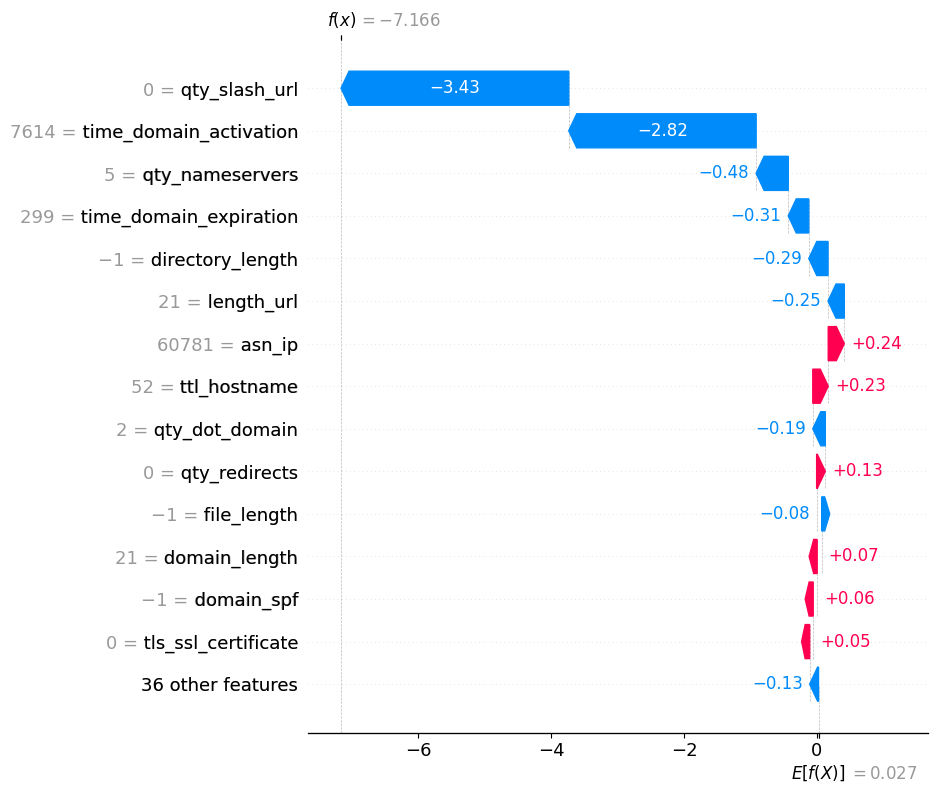

In [13]:

# Select one test sample
sample_index = 0
X_local = X_test.iloc[[sample_index]]
actual_label = int(y_test.iloc[sample_index])

predicted_label = int(final_model.predict(X_local)[0])
phishing_probability = float(final_model.predict_proba(X_local)[0, 1])

print("Test sample index:", X_local.index[0])
print("Actual label:", actual_label, "(Phishing)" if actual_label == 1 else "(Legitimate)")
print("Predicted label:", predicted_label, "(Phishing)" if predicted_label == 1 else "(Legitimate)")
print(f"Predicted phishing probability: {phishing_probability:.4f}")

# Calculate SHAP values for this sample
local_shap_values = explainer.shap_values(X_local)

# Waterfall plot for the positive-class output
base_value = explainer.expected_value
if isinstance(base_value, (list, np.ndarray)):
    base_value = np.asarray(base_value).flatten()[-1]

local_values = np.asarray(local_shap_values).reshape(-1)

local_explanation = shap.Explanation(
    values=local_values,
    base_values=float(base_value),
    data=X_local.iloc[0].to_numpy(),
    feature_names=X_local.columns.tolist()
)

shap.plots.waterfall(local_explanation, max_display=15)


###Step 7 conclusion — SHAP explanations
1. Global feature importance

- qty_slash_url had the highest average SHAP importance, followed by time_domain_activation.



- URL structure and length, domain characteristics, and hostname-related features also contributed to model predictions.



- Mean absolute SHAP measures the magnitude of a feature's influence, not whether it pushes a prediction toward phishing or legitimate. The summary plot's direction and colour provide that additional information.

2. Local explanation

For the selected test sample:
- Actual label: Legitimate (0)
- Predicted label: Legitimate (0)
- Predicted phishing probability: 0.0008 (0.08%)

XGBoost correctly classified this sample as legitimate and assigned a very low phishing probability. The waterfall plot explains which individual features pushed this prediction toward or away from phishing.

**Overall conclusion:**

SHAP provides interpretability for the selected XGBoost model by identifying influential features globally and explaining individual predictions locally.

This supports PhishGuard's goal of making phishing detection more transparent rather than returning only a classification label.

One important distinction: these results explain the model's behaviour; they do not prove that the identified features cause phishing activity.

##Step 8 — Select and save the final model

We'll create a folder containing:
- phishguard_xgboost.joblib — trained XGBoost model.
- phishguard_config.json — feature names, feature order, target labels, and model details.
- phishguard_metrics.json — evaluation metrics from Step 5.

###8.1 Save the model and configuration

In [14]:

import os
import json
import joblib
import pandas as pd

# Create an export folder
os.makedirs("phishguard_export", exist_ok=True)

# Select the final candidate
final_model = trained_models["XGBoost"]
final_model_path = "phishguard_export/phishguard_xgboost.joblib"

# Save the trained model
joblib.dump(final_model, final_model_path)

# Preserve the exact feature order used during training
feature_columns = X_train_balanced.columns.tolist()

# Website integration configuration
config = {
    "project": "PhishGuard",
    "selected_model": "XGBoost",
    "model_file": "phishguard_xgboost.joblib",
    "n_features": len(feature_columns),
    "feature_columns": feature_columns,
    "target_column": "phishing",
    "class_labels": {
        "0": "Legitimate",
        "1": "Phishing"
    },
    "positive_class": 1,
    "probability_output": "predict_proba",
    "training_balance": "Random undersampling to 50:50",
    "random_state": 42
}

config_path = "phishguard_export/phishguard_config.json"

with open(config_path, "w") as f:
    json.dump(config, f, indent=4)

# Save evaluation metrics from Step 5
metrics_to_save = [
    "Model", "Accuracy", "Precision", "Recall",
    "F1 Score", "ROC-AUC",
    "Prediction Time (seconds)"
]

metrics_path = "phishguard_export/phishguard_metrics.json"

results_df[metrics_to_save].to_json(
    metrics_path,
    orient="records",
    indent=4
)

print("Model saved:", final_model_path)
print("Configuration saved:", config_path)
print("Metrics saved:", metrics_path)
print("Number of required features:", len(feature_columns))
print("\nExport folder contents:")
print(os.listdir("phishguard_export"))


Model saved: phishguard_export/phishguard_xgboost.joblib
Configuration saved: phishguard_export/phishguard_config.json
Metrics saved: phishguard_export/phishguard_metrics.json
Number of required features: 50

Export folder contents:
['phishguard_xgboost.joblib', 'phishguard_metrics.json', 'phishguard_config.json']


###8.2 Verify the saved model

In [15]:

# Reload the saved model
loaded_model = joblib.load(
    "phishguard_export/phishguard_xgboost.joblib"
)

# Test with one sample from the existing test set
test_sample = X_test.iloc[[0]]

original_prediction = final_model.predict(test_sample)[0]
loaded_prediction = loaded_model.predict(test_sample)[0]

original_probability = final_model.predict_proba(test_sample)[0, 1]
loaded_probability = loaded_model.predict_proba(test_sample)[0, 1]

print("Original model prediction:", int(original_prediction))
print("Reloaded model prediction:", int(loaded_prediction))
print(f"Original phishing probability: {original_probability:.8f}")
print(f"Reloaded phishing probability: {loaded_probability:.8f}")

assert original_prediction == loaded_prediction
assert abs(original_probability - loaded_probability) < 1e-7

print("\nVerification successful: saved model matches original model.")


Original model prediction: 0
Reloaded model prediction: 0
Original phishing probability: 0.00077196
Reloaded phishing probability: 0.00077196

Verification successful: saved model matches original model.
